# Phase 3: EDA + topic modeling (Reddit)
Based on sir's "2 - Exploratory Data Analysis.ipynb". Mapping: airline = state, tweet date = post/reply date,
airline_sentiment = VADER label, negativereason = LDA topic.

Put this notebook in the `Social Media Data` folder (so `reddit_keywords` imports). Outputs go to `Social Media Data/phase3/`.

### Install (uncomment and run once)
`--no-deps` stops pyLDAvis from pulling in gensim, which can change your numpy version.

In [1]:
%pip install nltk seaborn wordcloud funcy numexpr jinja2
%pip install --no-deps pyLDAvis

  Using cached nltk-3.10.4-py3-none-any.whl.metadata (5.0 kB)
  Using cached seaborn-0.13.2-py3-none-any.whl.metadata (5.4 kB)
  Using cached wordcloud-1.9.6-cp311-cp311-win_amd64.whl.metadata (3.5 kB)
  Using cached funcy-2.1-py3-none-any.whl.metadata (6.3 kB)
  Using cached numexpr-2.14.2-cp311-cp311-win_amd64.whl.metadata (9.2 kB)
  Using cached jinja2-3.1.6-py3-none-any.whl.metadata (2.9 kB)
  Using cached click-8.5.1-py3-none-any.whl.metadata (2.6 kB)
Using cached nltk-3.10.4-py3-none-any.whl (1.7 MB)
Using cached seaborn-0.13.2-py3-none-any.whl (294 kB)
Using cached wordcloud-1.9.6-cp311-cp311-win_amd64.whl (306 kB)
Using cached funcy-2.1-py3-none-any.whl (29 kB)
Using cached numexpr-2.14.2-cp311-cp311-win_amd64.whl (157 kB)
Using cached jinja2-3.1.6-py3-none-any.whl (134 kB)
Using cached click-8.5.1-py3-none-any.whl (126 kB)

   ----------------------------------------  0/11 [funcy]
   --- ------------------------------------  1/11 [tqdm]
   --- ---------------------------------

### 1. Setup

In [2]:
import warnings, re
from functools import lru_cache
from pathlib import Path
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.decomposition import LatentDirichletAllocation

import nltk
from nltk.corpus import stopwords as nltk_stopwords
from nltk.stem import WordNetLemmatizer
from nltk.sentiment import SentimentIntensityAnalyzer
for pkg in ["stopwords", "wordnet", "omw-1.4", "vader_lexicon"]:
    nltk.download(pkg, quiet=True)

from reddit_keywords import HERE, load_posts, tag      # same tagger as Phase 1 and 2

sns.set(rc={"figure.figsize": (12, 6)})
BASE  = HERE.parent                                    # the "US Elections" folder
REPL  = HERE / "phase2" / "replies"
OUT   = HERE / "phase3"
OUT.mkdir(exist_ok=True)

YEARS  = [2012, 2016, 2020, 2024]
CUTOFF = {2012: "2012-11-06", 2016: "2016-11-08", 2020: "2020-11-03", 2024: "2024-11-05"}
REBUILD = False          # True = redo cleaning + VADER even if the cache exists

### 2. Load posts and replies

In [3]:
posts = tag(load_posts())
posts = posts[["id", "year", "state", "subreddit", "created_utc", "text", "removed",
               "elec", "cand", "num_comments"]]

files = sorted(REPL.glob("20*.csv"))
if len(files) < 204:
    print(f"WARNING: {len(files)} of 204 reply files. Re-run this notebook once Phase 2 is done.")
replies = pd.concat([pd.read_csv(f, dtype={"id": str, "post_id": str}) for f in files],
                    ignore_index=True)
replies = replies[~replies.body.isin(["[removed]", "[deleted]"])]       # drop removed replies
replies = replies.rename(columns={"body": "text"})

# election discussion = election posts + the replies on them
texts = pd.concat([
    posts[posts.elec].assign(kind="post", post_id=lambda d: d.id),
    replies.assign(kind="reply"),
], ignore_index=True)[["id", "post_id", "kind", "year", "state", "created_utc", "text"]]
texts["text"] = texts.text.fillna("").astype(str)
texts["date"] = pd.to_datetime(texts.created_utc, unit="s").dt.date
print(f"{len(posts):,} posts ({posts.elec.sum():,} election) | {len(replies):,} replies kept")
print(texts.groupby(["year", "kind"]).size().unstack())

298,553 posts (41,138 election) | 783,626 replies kept
kind   post   reply
year               
2012   1621   13922
2016   4257   48896
2020  12104  188227
2024  23156  532581


### 3. Cleaning functions (sir's `clean_tweets`, fixed for Reddit and pandas 2+)

In [4]:
STATES = sorted(posts.state.unique())
EXTRA_STOP = {
    # Reddit and web leftovers
    "removed", "deleted", "reddit", "subreddit", "http", "https", "www", "com", "org",
    "amp", "gt", "lt", "nbsp", "x200b", "edit", "op", "imgur", "jpg", "png",
    # contractions after apostrophes are stripped ("don't" becomes "dont")
    "dont", "im", "ive", "id", "youre", "theyre", "thats", "doesnt", "didnt", "isnt",
    "cant", "wont", "wouldnt", "shouldnt", "arent", "wasnt", "hes", "shes", "theres", "lets",
    # filler words that swamp the topics (edit this list after looking at the word counts)
    "would", "could", "also", "get", "got", "like", "one", "even", "really", "go", "going",
    "say", "said", "think", "know", "make", "much", "well", "thing", "way", "lot", "still",
    "yeah", "yes", "oh", "lol", "actually", "pretty", "sure", "want", "need", "see", "u",
}
ABBR = ["al", "ak", "az", "ar", "ca", "co", "ct", "de", "dc", "fl", "ga", "hi", "id", "il", "in",
        "ia", "ks", "ky", "la", "me", "md", "ma", "mi", "mn", "ms", "mo", "mt", "ne", "nv", "nh",
        "nj", "nm", "ny", "nc", "nd", "oh", "ok", "or", "pa", "ri", "sc", "sd", "tn", "tx", "ut",
        "vt", "va", "wa", "wv", "wi", "wy"]
STATE_WORDS = ({w for s in STATES for w in s.lower().split()}
               | {s.lower() for s in posts.subreddit.dropna().unique()} | set(ABBR))
STOP = set(nltk_stopwords.words("english")) | EXTRA_STOP | STATE_WORDS

lemmatizer = WordNetLemmatizer()

@lru_cache(maxsize=None)            # each distinct word is lemmatized once, not millions of times
def lemma(w):
    for pos in ("v", "a", "n"):     # same order as sir: verbs, adjectives, nouns
        w = lemmatizer.lemmatize(w, pos)
    return w

def clean_one(t):
    words = []
    for w in t.split():
        if len(w) < 2 or w in STOP:
            continue
        w = lemma(w)
        if w not in STOP:
            words.append(w)
    return " ".join(words)

def clean_texts(s):
    s = (s.str.lower()
          .str.replace(r"https?://\S+|www\.\S+", " ", regex=True)   # links
          .str.replace(r"\b[ur]/\w+", " ", regex=True)              # u/user, r/sub
          .str.replace(r"&\w+;", " ", regex=True)                   # &amp; &gt;
          .str.replace(r"['’]", "", regex=True)                # don't becomes dont
          .str.replace(r"[^a-z\s]", " ", regex=True))               # numbers, punctuation
    return s.map(clean_one)

### 4. Clean + VADER on raw text (about 5 to 10 min the first time, then loads from the cache)

In [5]:
CACHE = OUT / f"texts_{len(files)}files.pkl"     # rebuilds by itself once all 204 files exist
if CACHE.exists() and not REBUILD:
    texts = pd.read_pickle(CACHE)
    print("loaded", CACHE.name, f"({len(texts):,} texts)")
else:
    texts["cleaned_text"] = clean_texts(texts.text)
    texts["n_tokens"] = texts.cleaned_text.str.split().str.len()
    senti = SentimentIntensityAnalyzer()
    scores = [senti.polarity_scores(t) for t in texts.text]     # raw text, not cleaned
    for k in ["neg", "neu", "pos", "compound"]:
        texts[k] = [d[k] for d in scores]
    texts["sentiment"] = np.select([texts.compound >= 0.05, texts.compound <= -0.05],
                                   ["positive", "negative"], default="neutral")
    texts.to_pickle(CACHE)
    print("saved", CACHE.name)

print(texts.loc[[0, len(texts) - 1], ["text", "cleaned_text", "compound", "sentiment"]].values)

saved texts_202files.pkl
[["Cullman mayoral candidate says Jerry Springer show appearance with her lover and his wife shouldn't hurt her campaign."
  'cullman mayoral candidate jerry springer show appearance lover wife hurt campaign'
  0.7633 'positive']
 ["They're not doing it to see your ballot.  They're doing it so that husbands can see their wives' ballots."
  'ballot husband wive ballot' 0.0 'neutral']]


### 5. Counts and election share per state and year

       posts  election_posts  replies  election_texts
year                                                 
2012   16290            1621    13922           15543
2016   30673            4257    48896           53153
2020  104003           12104   188227          200331
2024  147587           23156   532581          555737

median per state:
      election_posts  replies  election_texts  elec_share
year                                                     
2012            19.0     92.0           115.0       0.103
2016            60.0    504.0           563.0       0.145
2020           158.0   2175.0          2284.0       0.104
2024           198.0   5454.0          5665.0       0.114


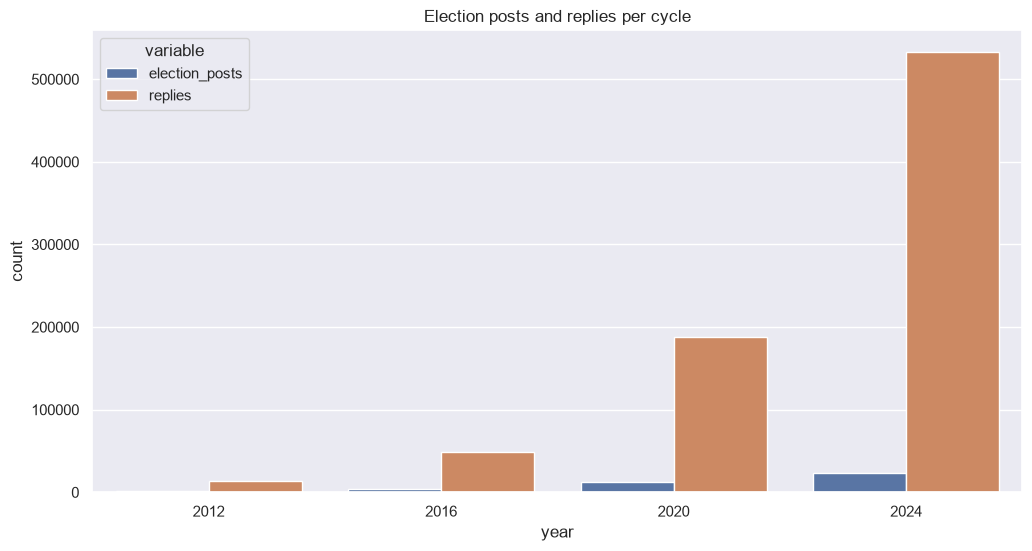

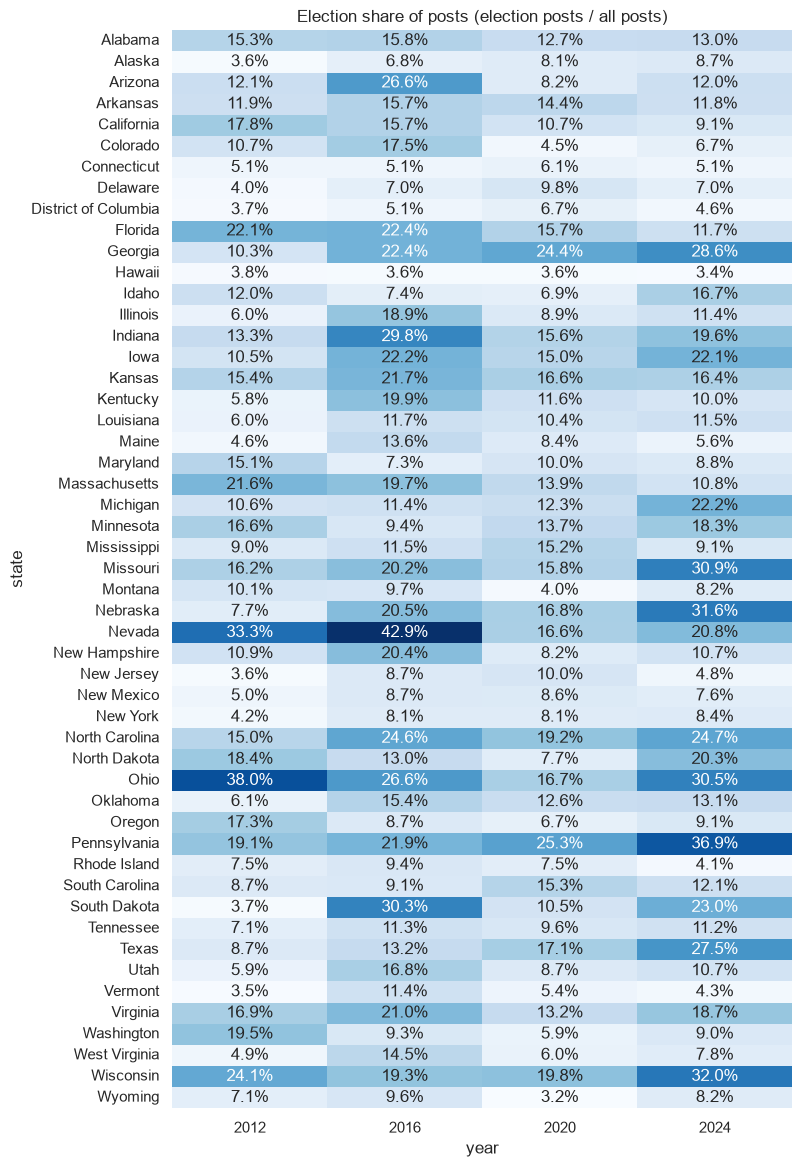

In [6]:
counts = (posts.groupby(["year", "state"])
               .agg(posts=("id", "size"), election_posts=("elec", "sum"))
               .join(texts[texts.kind == "reply"].groupby(["year", "state"]).size().rename("replies"))
               .fillna({"replies": 0}).astype(int)
               .reset_index())
counts["elec_share"]      = counts.election_posts / counts.posts   # posts only: replies exist
counts["election_texts"]  = counts.election_posts + counts.replies # only on election posts
counts.to_csv(OUT / "counts_state_year.csv", index=False)

print(counts.groupby("year")[["posts", "election_posts", "replies", "election_texts"]].sum())
print("\nmedian per state:")
print(counts.groupby("year")[["election_posts", "replies", "election_texts", "elec_share"]]
            .median().round(3))

ax = sns.barplot(data=counts.melt(id_vars="year", value_vars=["election_posts", "replies"]),
                 x="year", y="value", hue="variable", estimator="sum", errorbar=None)
ax.set(title="Election posts and replies per cycle", ylabel="count")
plt.show(); plt.close()

plt.figure(figsize=(8, 14))
sns.heatmap(counts.pivot(index="state", columns="year", values="elec_share"),
            cmap="Blues", annot=True, fmt=".1%", cbar=False)
plt.title("Election share of posts (election posts / all posts)")
plt.show(); plt.close()

### 6. Over time: daily election share and sentiment, last 90 days of each cycle

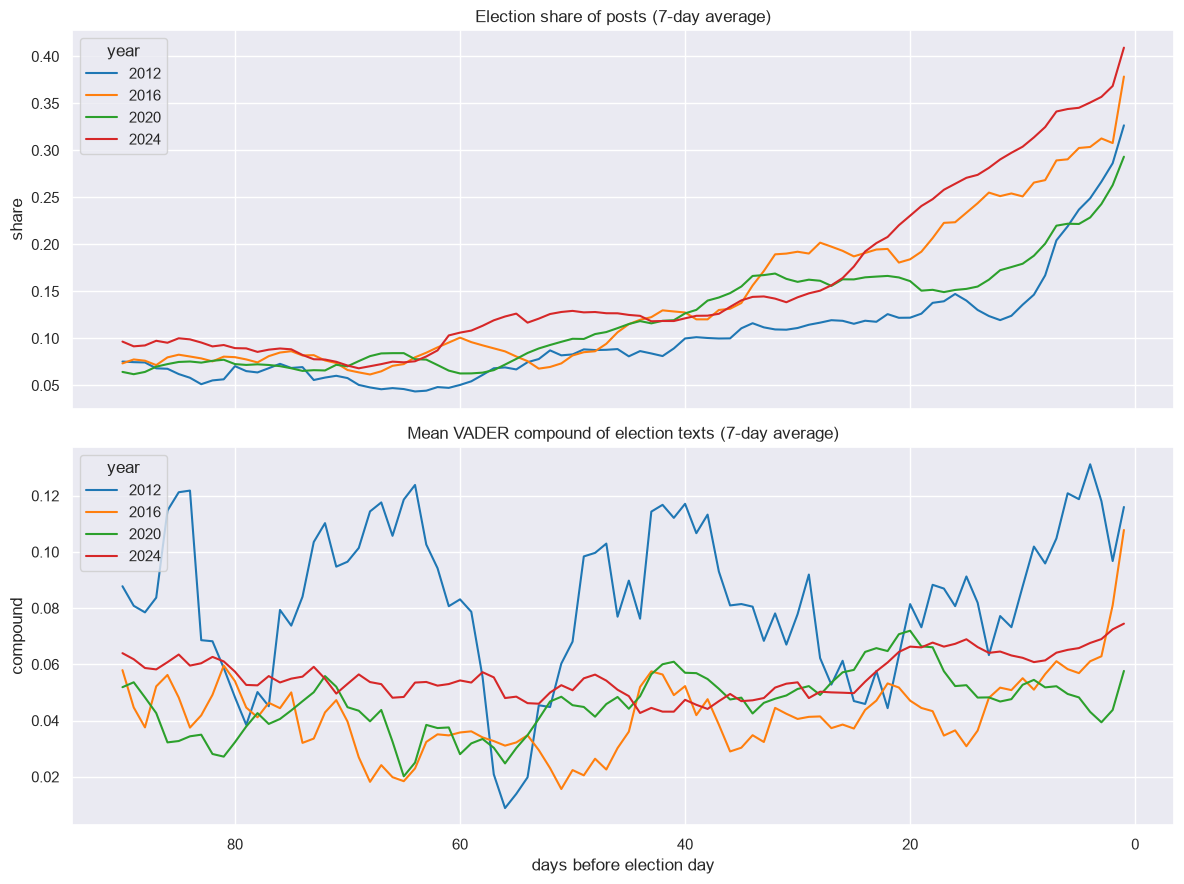

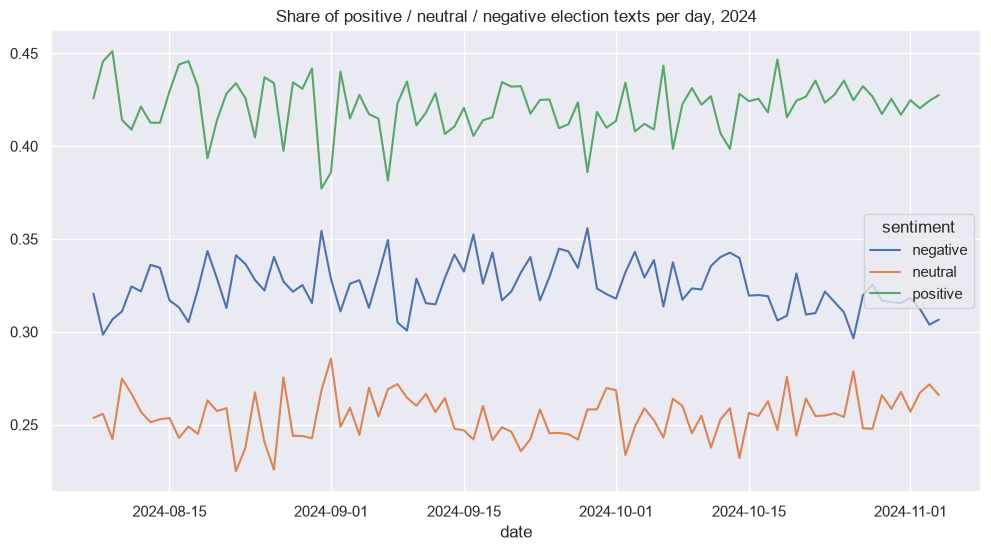

In [7]:
def days_left(df):
    cut = df.year.map(lambda y: pd.Timestamp(CUTOFF[y]).date())
    return (pd.to_datetime(cut) - pd.to_datetime(df.date)).dt.days

posts["date"] = pd.to_datetime(posts.created_utc, unit="s").dt.date
posts["days_left"] = days_left(posts)
texts["days_left"] = days_left(texts)

share = posts.groupby(["year", "days_left"]).elec.mean().rename("elec_share").reset_index()
sent  = texts.groupby(["year", "days_left"]).compound.mean().rename("sentiment").reset_index()
for d, col in [(share, "elec_share"), (sent, "sentiment")]:
    d[col + "_7d"] = d.groupby("year")[col].transform(lambda s: s.rolling(7, min_periods=1).mean())

fig, axes = plt.subplots(2, 1, figsize=(12, 9), sharex=True)
sns.lineplot(data=share, x="days_left", y="elec_share_7d", hue="year", palette="tab10", ax=axes[0])
sns.lineplot(data=sent,  x="days_left", y="sentiment_7d",  hue="year", palette="tab10", ax=axes[1])
axes[0].set(title="Election share of posts (7-day average)", ylabel="share")
axes[1].set(title="Mean VADER compound of election texts (7-day average)", ylabel="compound",
            xlabel="days before election day")
axes[1].invert_xaxis()
plt.tight_layout(); plt.show(); plt.close()

# sir's "sentiments across time" chart, one cycle at a time (as shares, since volume grows)
YEAR = 2024
x = (texts[texts.year == YEAR].groupby("date").sentiment.value_counts(normalize=True)
          .unstack())
x.plot(title=f"Share of positive / neutral / negative election texts per day, {YEAR}")
plt.show(); plt.close()

### 7. Turnout groups and battleground status (same rules as the main notebook)

In [8]:
PE = BASE / "Official Turnout Data" / "Presidential Elections"
PRES_FILES = {2012: "Turnout_2012G_v1.0.csv", 2016: "Turnout_2016G_v1.0.csv",
              2020: "Turnout_2020G_v1.2.csv", 2024: "Turnout_2024G_v0.4.csv"}

def num(s):
    return pd.to_numeric(s.astype(str).str.replace(r"[,%]", "", regex=True).str.strip(),
                         errors="coerce")

def read_vep(path, year):
    d = pd.read_csv(path)
    d.columns = [c.strip().upper() for c in d.columns]
    d["state"] = d.STATE.astype(str).str.strip().str.replace(r"\*+$", "", regex=True)
    d["turnout"] = num(d.VEP_TURNOUT_RATE)
    d["year"] = year
    return d.loc[d.state.isin(STATES), ["state", "year", "turnout"]]

turn = pd.concat([read_vep(PE / f, y) for y, f in PRES_FILES.items()], ignore_index=True)

v = pd.read_csv(BASE / "Official Turnout Data" / "1976-2024-president.csv")
v = v[v.year.between(2008, 2020)]
v["state"] = v.state.str.title().str.replace(" Of ", " of ")
two = (v[v.party_simplified.isin(["DEMOCRAT", "REPUBLICAN"])]
         .groupby(["state", "year", "party_simplified"]).candidatevotes.sum().unstack())
margin = (100 * (two.DEMOCRAT - two.REPUBLICAN).abs() / two.sum(axis=1)).rename("margin_prev")
margin = margin.reset_index().assign(year=lambda d: d.year + 4)     # 2008 margin used for 2012

ctx = turn.merge(margin, on=["state", "year"], how="left")
ctx["battleground"] = np.where(ctx.margin_prev < 5, "battleground", "other")
ctx["turnout_group"] = (ctx.groupby("year").turnout
                           .transform(lambda s: pd.qcut(s, 3, labels=["low", "mid", "high"]).astype(str)))
assert len(ctx) == 204 and ctx.notna().all().all(), "turnout / margin merge is missing rows"
print(ctx.groupby("year").battleground.value_counts().unstack())

texts = texts.drop(columns=["battleground", "turnout_group", "turnout"], errors="ignore") \
             .merge(ctx[["state", "year", "turnout", "battleground", "turnout_group"]],
                    on=["state", "year"], how="left")

battleground  battleground  other
year                             
2012                     6     45
2016                     4     47
2020                    10     41
2024                     8     43


### 8. Stacked % sentiment bars (sir's `visualize_percentages`, fixed to use `df`)

sentiment          negative  neutral  positive
group                                         
2012 battleground     0.343    0.249     0.408
2012 other            0.324    0.212     0.464
2016 battleground     0.368    0.220     0.412
2016 other            0.342    0.225     0.433
2020 battleground     0.349    0.226     0.425
2020 other            0.335    0.236     0.429
2024 battleground     0.330    0.260     0.410
2024 other            0.317    0.253     0.430


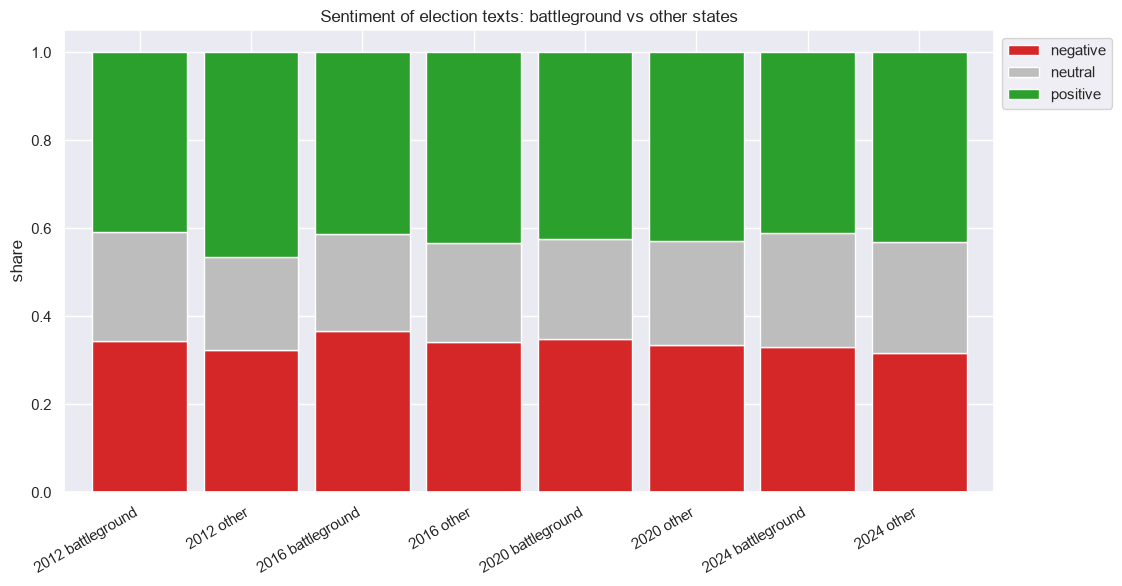

sentiment             negative  neutral  positive
label                                            
Delaware                 0.246    0.268     0.486
District of Columbia     0.257    0.275     0.468
Texas                    0.258    0.353     0.389
New Mexico               0.266    0.281     0.454
Montana                  0.273    0.229     0.498
Hawaii                   0.279    0.268     0.452
New Jersey               0.282    0.302     0.416
Arizona *                0.287    0.263     0.450
Oklahoma                 0.290    0.264     0.446
Kansas                   0.295    0.282     0.423
Alaska                   0.295    0.247     0.458
Tennessee                0.297    0.275     0.428
Vermont                  0.300    0.242     0.457
Wyoming                  0.301    0.246     0.453
Nevada *                 0.302    0.271     0.427
Washington               0.303    0.243     0.455
Minnesota                0.303    0.258     0.439
Illinois                 0.308    0.292     0.399


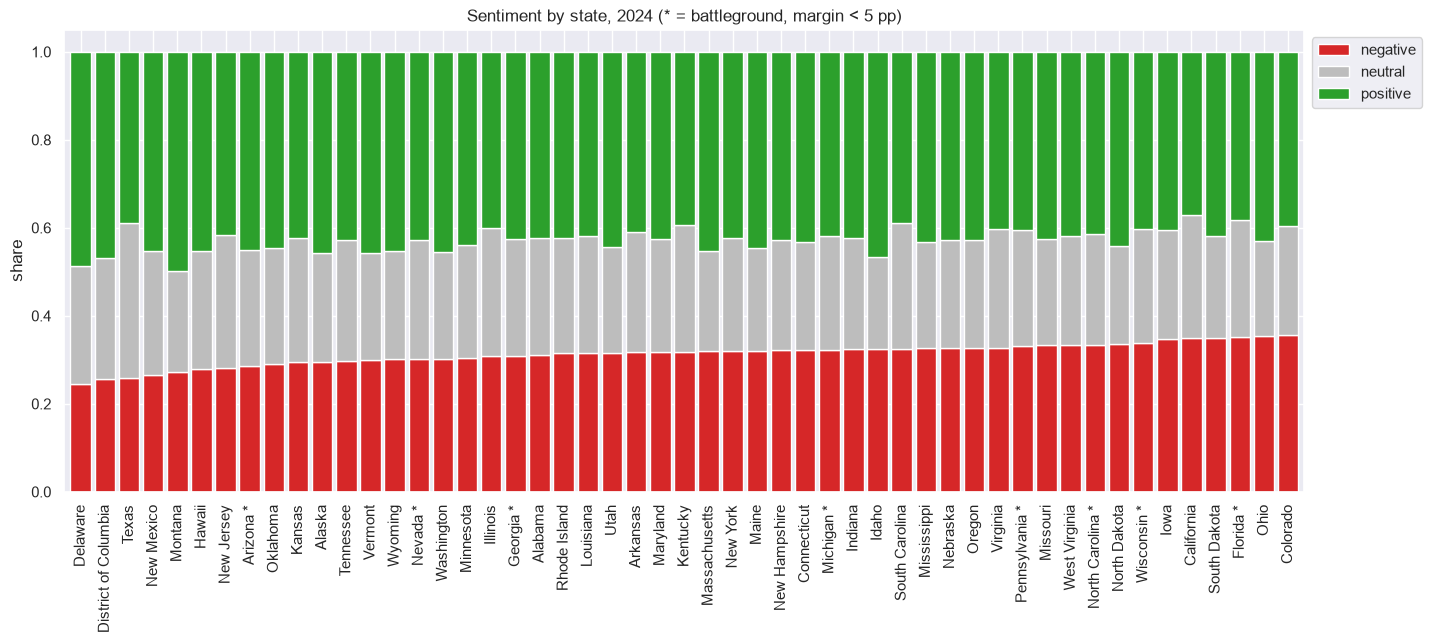

sentiment,negative,neutral,positive
label,,,
Delaware,0.245787,0.267868,0.486345
District of Columbia,0.257157,0.274723,0.468120
Texas,0.257819,0.352994,0.389187
New Mexico,0.265512,0.280904,0.453583
Montana,0.273050,0.229314,0.497636
Hawaii,0.279299,0.268346,0.452355
New Jersey,0.281633,0.302161,0.416206
Arizona *,0.286704,0.263279,0.450016
Oklahoma,0.289850,0.264078,0.446072


In [9]:
ORDER = ["negative", "neutral", "positive"]
COLORS = {"negative": "#d62728", "neutral": "#bdbdbd", "positive": "#2ca02c"}

def visualize_percentages(df, x, hue, title=None, sort_by=None, figsize=(12, 6)):
    pct = pd.crosstab(df[x], df[hue], normalize="index")
    pct = pct[[c for c in ORDER if c in pct.columns]]
    if sort_by:
        pct = pct.sort_values(sort_by)
    print(pct.round(3))
    ax = pct.plot(kind="bar", stacked=True, figsize=figsize,
                  color=[COLORS[c] for c in pct.columns], width=0.85)
    ax.set(title=title, ylabel="share", xlabel="")
    ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
    plt.xticks(rotation=90 if len(pct) > 10 else 30, ha="center" if len(pct) > 10 else "right")
    plt.show(); plt.close()
    return pct

texts["group"] = texts.year.astype(str) + " " + texts.battleground
visualize_percentages(texts, "group", "sentiment",
                      title="Sentiment of election texts: battleground vs other states")

YEAR = 2024
d = texts[texts.year == YEAR].copy()
d["label"] = np.where(d.battleground == "battleground", d.state + " *", d.state)
visualize_percentages(d, "label", "sentiment", sort_by="negative", figsize=(16, 6),
                      title=f"Sentiment by state, {YEAR} (* = battleground, margin < 5 pp)")

### 9. Word clouds + unigrams + bigrams: high vs low turnout states

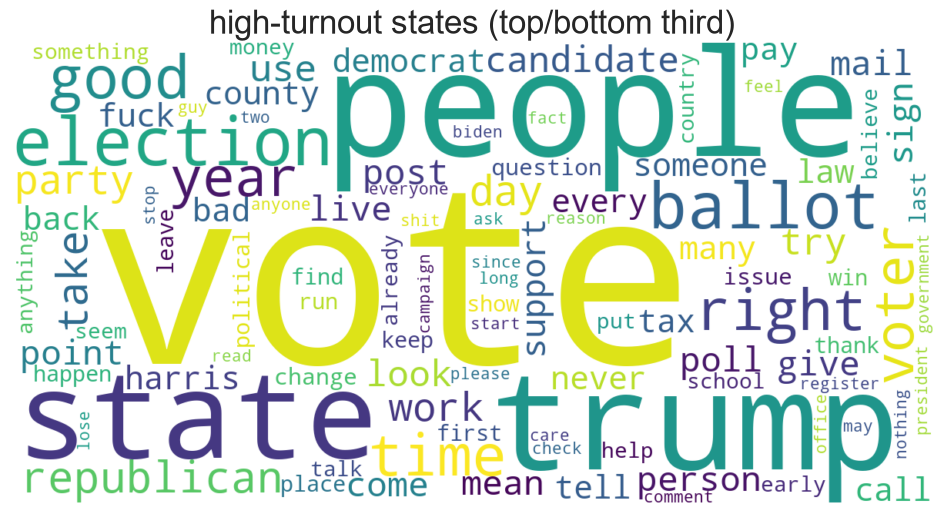

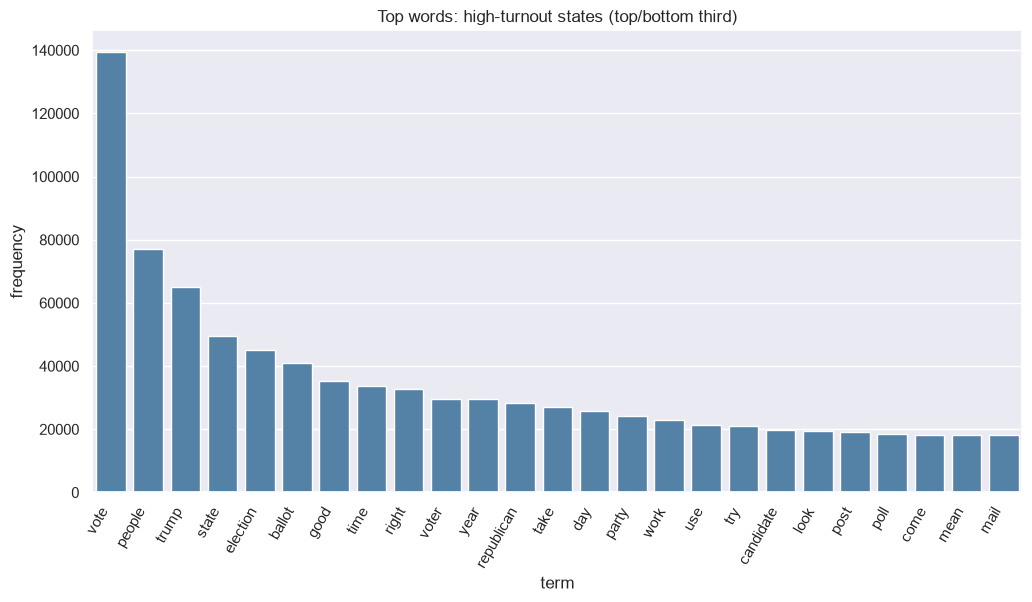

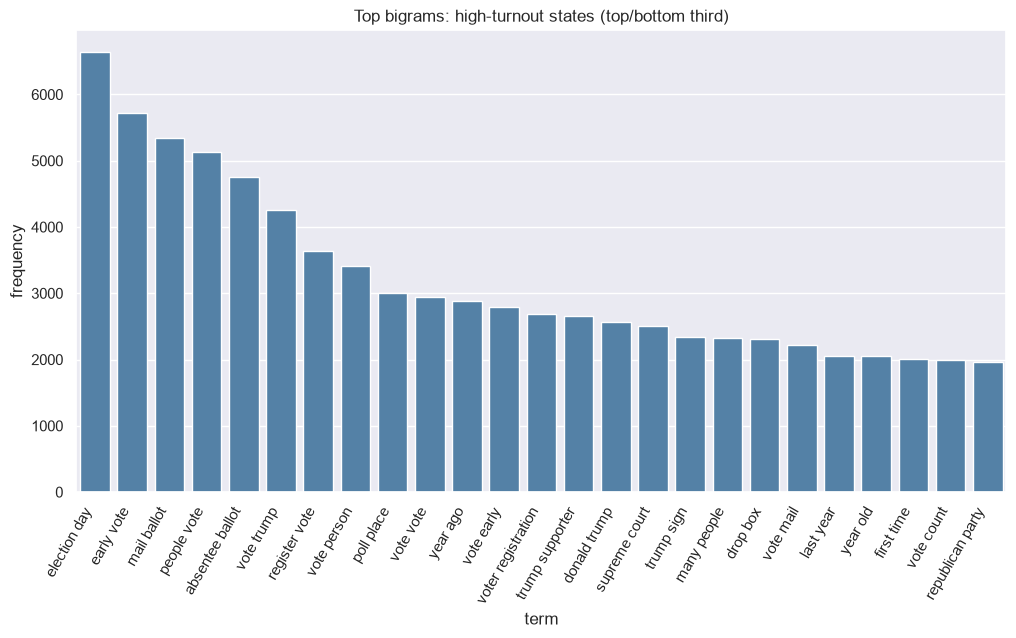

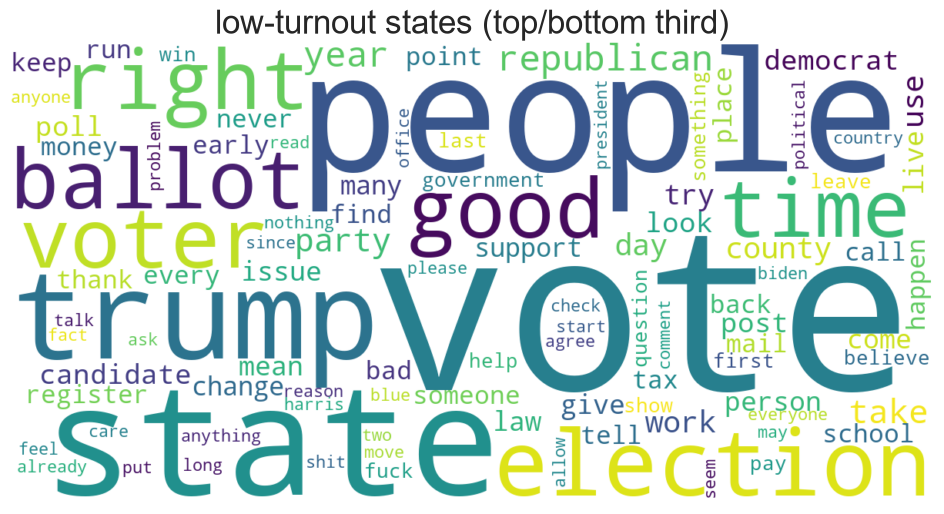

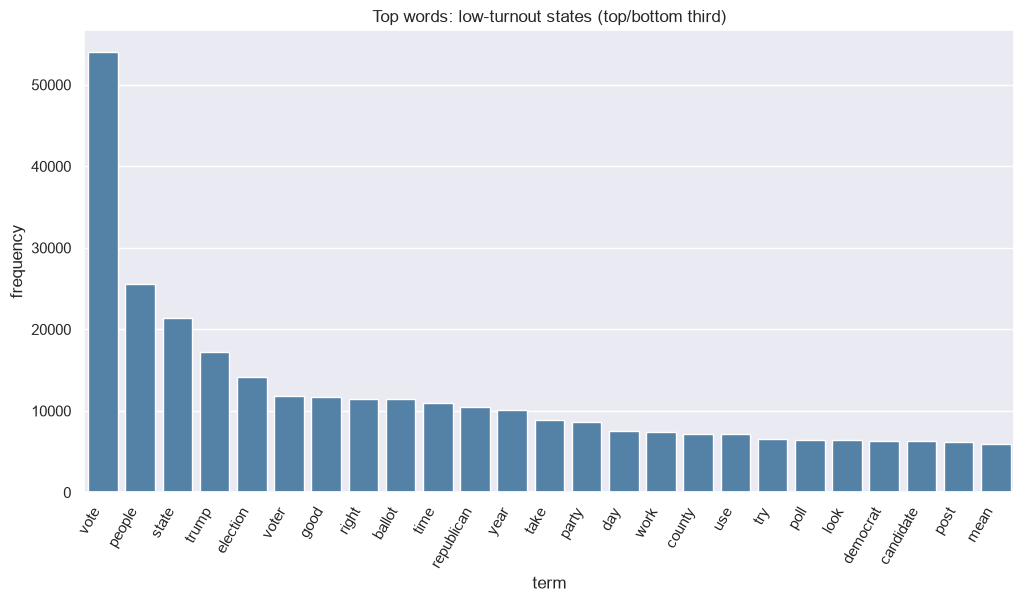

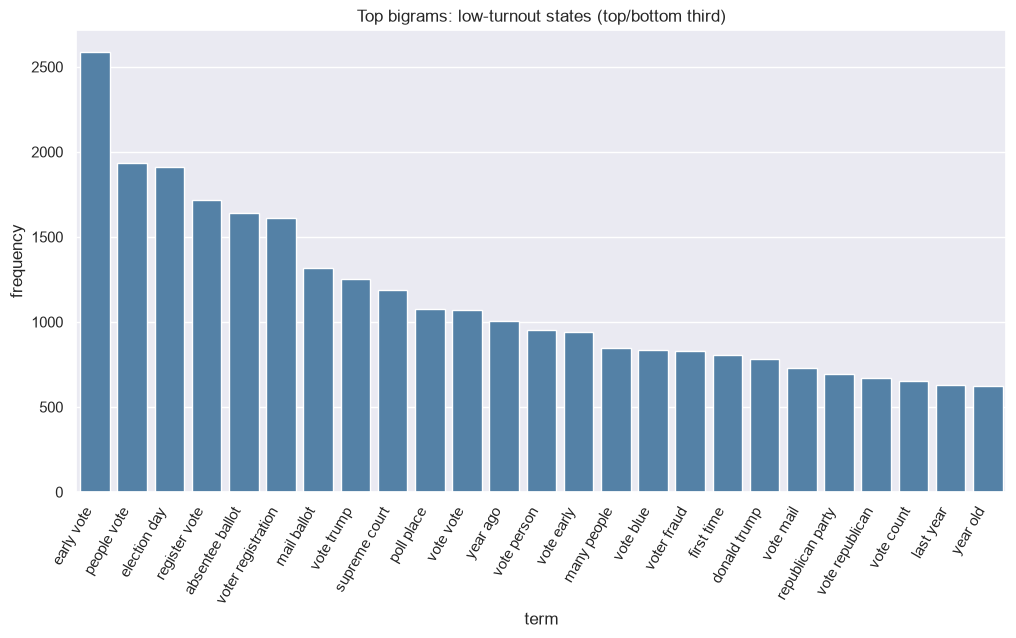

more common in HIGH-turnout states: mcas, alsobrooks, ayotte, unflair, hovde, markey, sununu, tillis, dfl, dane, cao, mainer, evers, youngkin, manchester, psychedelics, ernst, mccrory, waukesha, hogan, ricketts, minnesotan, iowan, flaired, nebraskan
more common in LOW-turnout states:  landry, braun, holcomb, rainwater, oklahoman, hoosier, gmo, hawaiian, tulsa, texan, harrison, abbott, sq, cotton, lindsey, dallas, notarize, houston, graham, cuck, walter, proposition, cruz, prop, notary


In [10]:
def visualize_frequency(matrix, vectorizer, title=None, top=25):
    total = np.asarray(matrix.sum(axis=0)).ravel()
    freq = (pd.DataFrame({"term": vectorizer.get_feature_names_out(), "frequency": total})
              .sort_values("frequency", ascending=False).head(top))
    ax = sns.barplot(data=freq, x="term", y="frequency", color="steelblue")
    if title:
        ax.set_title(title)
    plt.xticks(rotation=60, ha="right")
    plt.show(); plt.close()
    return freq

def create_wordcloud(matrix, vectorizer, max_words=100, title=None):
    total = np.asarray(matrix.sum(axis=0)).ravel()
    wc = WordCloud(background_color="white", max_words=max_words, width=1200, height=600)
    wc.generate_from_frequencies(dict(zip(vectorizer.get_feature_names_out(), total)))
    plt.imshow(wc, interpolation="bilinear")
    if title:
        plt.title(title, size=24)
    plt.axis("off")
    plt.show(); plt.close()

def visualize_texts(df, title=""):
    v1 = CountVectorizer(ngram_range=(1, 1), max_features=2000)
    m1 = v1.fit_transform(df.cleaned_text)
    v2 = CountVectorizer(ngram_range=(2, 2), max_features=2000)
    m2 = v2.fit_transform(df.cleaned_text)
    create_wordcloud(m1, v1, title=title)
    visualize_frequency(m1, v1, title=f"Top words: {title}")
    visualize_frequency(m2, v2, title=f"Top bigrams: {title}")

for g in ["high", "low"]:
    visualize_texts(texts[texts.turnout_group == g], title=f"{g}-turnout states (top/bottom third)")

# words that set the two groups apart (log ratio of shares, smoothed)
cv = CountVectorizer(min_df=50)
m = cv.fit_transform(texts.cleaned_text)
hi = np.asarray(m[(texts.turnout_group == "high").to_numpy()].sum(axis=0)).ravel() + 1
lo = np.asarray(m[(texts.turnout_group == "low").to_numpy()].sum(axis=0)).ravel() + 1
lr = pd.Series(np.log2((hi / hi.sum()) / (lo / lo.sum())), index=cv.get_feature_names_out())
lr = lr[(hi + lo) >= 200]
print("more common in HIGH-turnout states:", ", ".join(lr.nlargest(25).index))
print("more common in LOW-turnout states: ", ", ".join(lr.nsmallest(25).index))

### 10. LDA: try k = 5 to 8 on a sample, then pick k (a few minutes)

In [11]:
docs = texts[texts.n_tokens >= 5].copy()               # very short replies carry no topic
print(f"{len(docs):,} election texts with 5+ words ({len(docs)/len(texts):.0%})")

# fit on up to 15,000 texts per cycle so 2024 doesn't drown out 2012
fit_idx  = pd.Index(np.concatenate([g.sample(min(len(g), 15000), random_state=42).index
                                    for _, g in docs.groupby("year")]))
test_idx = docs.drop(fit_idx).sample(10000, random_state=42).index

vectorizer = CountVectorizer(max_df=0.95, min_df=20, max_features=5000)
vectorizer.fit(docs.loc[fit_idx, "cleaned_text"])
vocab = vectorizer.get_feature_names_out()
X_fit  = vectorizer.transform(docs.loc[fit_idx, "cleaned_text"])
X_test = vectorizer.transform(docs.loc[test_idx, "cleaned_text"])
print("doc-term matrix:", X_fit.shape)

def top_words(lda, n=12):
    return [[vocab[i] for i in topic.argsort()[-n:][::-1]] for topic in lda.components_]

runs = {}
for k in range(5, 9):
    lda = LatentDirichletAllocation(n_components=k, learning_method="online",
                                    random_state=42).fit(X_fit)
    runs[k] = lda
    # sklearn's perplexity often rises with k, so pick k by how readable the topics are
    print(f"\n===== k = {k} | held-out perplexity {lda.perplexity(X_test):,.0f}")
    for i, words in enumerate(top_words(lda)):
        print(f"  topic {i}: {', '.join(words)}")

596,629 election texts with 5+ words (72%)
doc-term matrix: (57263, 4959)

===== k = 5 | held-out perplexity 2,057
  topic 0: people, right, state, tax, good, money, school, government, take, give, law, amendment
  topic 1: people, work, job, gun, pay, great, family, group, business, live, company, high
  topic 2: vote, election, ballot, voter, day, poll, state, county, mail, people, time, register
  topic 3: trump, party, republican, post, candidate, democrat, win, biden, run, sign, please, political
  topic 4: state, people, trump, year, support, harris, local, court, big, law, change, lie

===== k = 6 | held-out perplexity 2,097
  topic 0: tax, money, school, state, pay, fund, rule, spend, year, government, million, business
  topic 1: work, job, maybe, people, high, world, service, black, small, large, great, use
  topic 2: vote, election, ballot, voter, day, poll, state, county, mail, register, early, time
  topic 3: trump, republican, party, post, democrat, candidate, biden, win,

### 11. Final model: set K, name the topics, assign every text

In [12]:
K = 6                                  # pick after reading the word lists above
lda = runs[K]
for i, words in enumerate(top_words(lda, 15)):
    print(f"topic {i}: {', '.join(words)}")

TOPIC_NAMES = {i: f"topic{i}" for i in range(K)}   # rename, e.g. {0: "ballot_logistics", ...}

X_all = vectorizer.transform(docs.cleaned_text)
doc_topic = lda.transform(X_all)
docs["topic"] = doc_topic.argmax(axis=1)
docs["topic_prob"] = doc_topic.max(axis=1)
docs["topic_name"] = docs.topic.map(TOPIC_NAMES)

# 15 clearest examples per topic, to help name them (open in Excel)
ex = (docs.sort_values("topic_prob", ascending=False).groupby("topic").head(15)
          .sort_values(["topic", "topic_prob"], ascending=[True, False]))
ex[["topic", "topic_name", "topic_prob", "year", "state", "kind", "text"]] \
  .to_csv(OUT / f"topic_examples_k{K}.csv", index=False, encoding="utf-8-sig")
print(docs.topic_name.value_counts(normalize=True).round(3))

topic 0: tax, money, school, state, pay, fund, rule, spend, year, government, million, business, cost, good, education
topic 1: work, job, maybe, people, high, world, service, black, small, large, great, use, family, local, stop
topic 2: vote, election, ballot, voter, day, poll, state, county, mail, register, early, time, person, question, candidate
topic 3: trump, republican, party, post, democrat, candidate, biden, win, president, fuck, support, please, campaign, american, run
topic 4: people, good, time, year, look, live, come, bad, sign, try, number, back, harris, never, area
topic 5: people, right, state, law, issue, gun, mean, happen, court, use, reason, change, believe, understand, case
topic_name
topic2    0.264
topic5    0.235
topic4    0.215
topic3    0.151
topic0    0.072
topic1    0.063
Name: proportion, dtype: float64


### 12. pyLDAvis (on the fitting sample). Skip this cell if pyLDAvis errors on pandas 3.

In [13]:
import pyLDAvis
topic_term = lda.components_ / lda.components_.sum(axis=1, keepdims=True)
doc_topic_fit = lda.transform(X_fit)
vis = pyLDAvis.prepare(topic_term, doc_topic_fit,
                       doc_lengths=np.asarray(X_fit.sum(axis=1)).ravel(),   # words, not characters
                       vocab=vocab, term_frequency=np.asarray(X_fit.sum(axis=0)).ravel(),
                       sort_topics=False)          # keep topic numbers the same as above
pyLDAvis.save_html(vis, str(OUT / f"lda_k{K}.html"))
print("saved", f"lda_k{K}.html")
# pyLDAvis.display(vis)          # uncomment to show inside the notebook

saved lda_k6.html


### 13. Topic shares per state-year (context features, 204 rows)

(204, 8) saved to C:\Users\Nicolas\Documents\1Thesis\US Elections\Social Media Data\phase3\topic_shares.csv


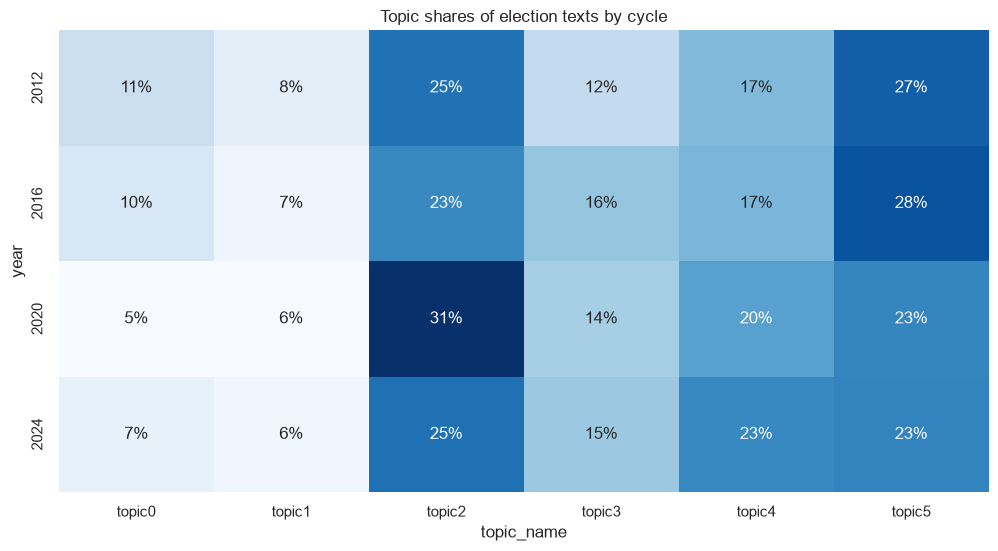

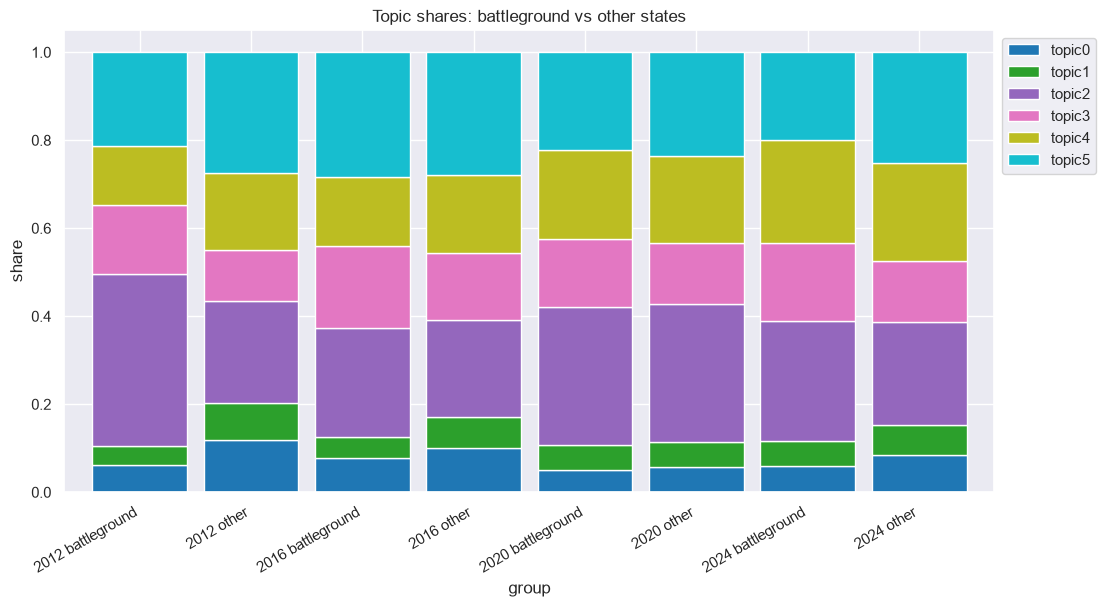

In [14]:
shares = (pd.crosstab([docs.year, docs.state], docs.topic_name, normalize="index")
            .add_prefix("topic_").add_suffix("_share")
            .reindex(pd.MultiIndex.from_product([YEARS, STATES], names=["year", "state"]))
            .fillna(0).reset_index())
shares.to_csv(OUT / "topic_shares.csv", index=False)
print(shares.shape, "saved to", OUT / "topic_shares.csv")

nat = docs.groupby("year").topic_name.value_counts(normalize=True).unstack()
sns.heatmap(nat, annot=True, fmt=".0%", cmap="Blues", cbar=False)
plt.title("Topic shares of election texts by cycle"); plt.show(); plt.close()

docs["group"] = docs.year.astype(str) + " " + docs.battleground
pct = pd.crosstab(docs.group, docs.topic_name, normalize="index")
pct.plot(kind="bar", stacked=True, width=0.85, colormap="tab10",
         title="Topic shares: battleground vs other states")
plt.legend(loc="upper left", bbox_to_anchor=(1, 1)); plt.ylabel("share")
plt.xticks(rotation=30, ha="right")
plt.show(); plt.close()

### Optional: compare topics with the Trends groups
This cell is for `US Elections Analysis.ipynb`, not this notebook. Paste it there after `model_df` exists.
It correlates topic shares with the Trends indices and turnout, after taking out each year's average.

```python
ts = pd.read_csv(BASE / "Social Media Data" / "phase3" / "topic_shares.csv")
chk = model_df.merge(ts, on=["state", "year"], how="left")
tcols = [c for c in ts.columns if c.startswith("topic_")]
trends = ["salience_index", "friction_index", "access_index", "candidate_v2_index", "turnout"]
dm = chk.groupby("year")[tcols + trends].transform(lambda s: s - s.mean())
print(dm.corr().loc[tcols, trends].round(2))
```